# Option 3: Support Vector Machine
Yang Xiao (yx752)

## Step 0: Import Libraries & Load Data

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score

RANDOM_STATE = 27
data_path = Path('../cornell-tech-cs-5785-combined-2026-ai-vs-human-text')
if not (data_path / 'train.csv').exists():
    data_path = Path('.')
train_df = pd.read_csv(data_path / 'train.csv')
test_df = pd.read_csv(data_path / 'test.csv')
unlabeled_df = pd.read_csv(data_path / 'unlabeled.csv')
print('Training:', train_df.shape, 'Test:', test_df.shape, 'Unlabeled:', unlabeled_df.shape)
print(train_df.label.value_counts().sort_index().to_string())
assert train_df.id.is_unique
assert not train_df[['text', 'label']].isna().any().any()

Training: (10000, 3) Test: (3000, 2) Unlabeled: (3000, 2)
label
0    5000
1    5000


## Step 1: Split the Training Data
Use the same stratified split as the logistic regression notebook: 8,000 training rows, 2,000 validation rows, and random state 27. All experiments below keep these validation rows fixed.

In [2]:
X = train_df.drop(columns=['label'])
y = train_df['label']
X_train, X_dev, y_train, y_dev = train_test_split(
    X, y, test_size=2000, random_state=RANDOM_STATE, stratify=y)
output_path = Path('svm_results')
output_path.mkdir(exist_ok=True)
X_dev[['id']].to_csv(output_path / 'val_ids.csv', index=False)
assert len(X_train) == 8000 and len(X_dev) == 2000
assert y_dev.value_counts().to_dict() == {0: 1000, 1: 1000}
print('Training rows:', len(X_train), '| Validation rows:', len(X_dev))

Training rows: 8000 | Validation rows: 2000


## Step 2: Represent the Text
I use word TF-IDF features with lowercase normalization and the default token pattern (words of at least two characters). I keep stop words and do not stem the text. Unigrams capture individual words, while bigrams can capture short phrases. Vocabulary and IDF are fitted only on training text.

I compare unigram and unigram/bigram features with four C values. Smaller C gives stronger regularization. AUROC uses the SVM decision scores, so it does not require a classification threshold.

In [3]:
def make_vectorizer(ngram_max):
    return TfidfVectorizer(ngram_range=(1, ngram_max), min_df=2,
                           max_features=100000, sublinear_tf=True)

def make_pipeline(ngram_max, C):
    return Pipeline([
        ('tfidf', make_vectorizer(ngram_max)),
        ('svm', LinearSVC(C=C, dual='auto', max_iter=10000,
                          random_state=RANDOM_STATE))])

## Step 3: Train and Tune Linear SVM
The validation AUROC selects the configuration. Feature extraction is shared across C values within each representation; total training time below includes feature fitting plus classifier fitting for that configuration.

In [4]:
results = []
for ngram_max in [1, 2]:
    start = time.perf_counter()
    vectorizer = make_vectorizer(ngram_max)
    train_features = vectorizer.fit_transform(X_train.text)
    dev_features = vectorizer.transform(X_dev.text)
    feature_seconds = time.perf_counter() - start
    for C in [0.01, 0.1, 1, 10]:
        model = LinearSVC(C=C, dual='auto', max_iter=10000,
                          random_state=RANDOM_STATE)
        start = time.perf_counter()
        model.fit(train_features, y_train)
        fit_seconds = time.perf_counter() - start
        results.append({
            'ngram_max': ngram_max, 'C': C,
            'train_auroc': roc_auc_score(y_train, model.decision_function(train_features)),
            'val_auroc': roc_auc_score(y_dev, model.decision_function(dev_features)),
            'train_seconds': feature_seconds + fit_seconds})
search_df = pd.DataFrame(results).sort_values(
    ['val_auroc', 'C', 'ngram_max'], ascending=[False, True, True])
print(search_df.to_string(index=False))
search_df.to_csv(output_path / 'search.csv', index=False)
best = search_df.iloc[0]
best_ngram, best_C = int(best.ngram_max), float(best.C)
print(f'Chosen: ngram_range=(1, {best_ngram}), C={best_C:g}')

 ngram_max     C  train_auroc  val_auroc  train_seconds
         2  1.00     1.000000   0.944737       2.603011
         2 10.00     1.000000   0.943315       2.643536
         2  0.10     0.994703   0.931427       2.576472
         1  1.00     0.999994   0.917543       0.798461
         1  0.10     0.982761   0.913354       0.774294
         1 10.00     1.000000   0.908116       0.843970
         2  0.01     0.958657   0.899522       2.565633
         1  0.01     0.929674   0.880022       0.768462
Chosen: ngram_range=(1, 2), C=1


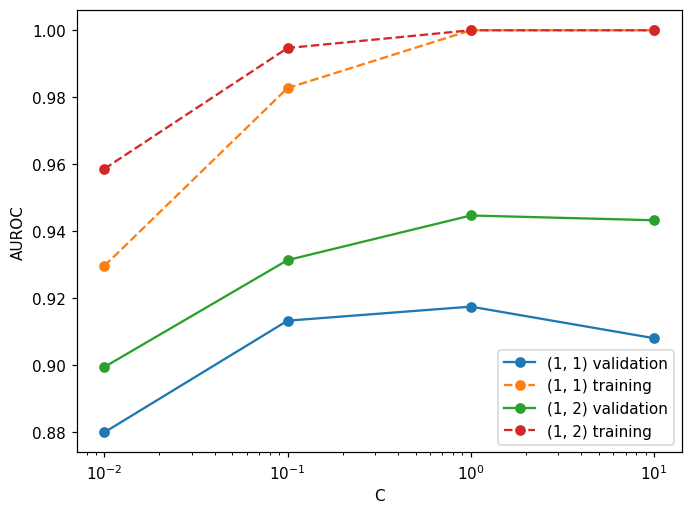

In [5]:
for ngram_max in [1, 2]:
    group = search_df[search_df.ngram_max == ngram_max].sort_values('C')
    plt.plot(group.C, group.val_auroc, 'o-', label=f'(1, {ngram_max}) validation')
    plt.plot(group.C, group.train_auroc, 'o--', label=f'(1, {ngram_max}) training')
plt.xscale('log')
plt.xlabel('C')
plt.ylabel('AUROC')
plt.legend()
plt.tight_layout()
plt.show()

## Step 4: Predict Probabilities
LinearSVC gives decision scores rather than probabilities. I use sigmoid calibration with three stratified folds inside the training partition. The full TF-IDF/SVM pipeline is refitted in each fold, so the calibration fold is excluded from vocabulary fitting as well. The validation partition is not used to fit calibration.

In [6]:
def make_calibrated_model():
    folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    return CalibratedClassifierCV(make_pipeline(best_ngram, best_C),
                                  method='sigmoid', cv=folds, ensemble=False)

calibrated_model = make_calibrated_model()
start = time.perf_counter()
calibrated_model.fit(X_train.text, y_train)
calibration_seconds = time.perf_counter() - start
dev_probability = calibrated_model.predict_proba(X_dev.text)[:, 1]
train_auc = roc_auc_score(y_train, calibrated_model.predict_proba(X_train.text)[:, 1])
dev_auc = roc_auc_score(y_dev, dev_probability)
print(f'Calibrated train AUROC: {train_auc:.6f}')
print(f'Calibrated validation AUROC: {dev_auc:.6f}')
print(f'Training including calibration: {calibration_seconds:.2f}s')

Calibrated train AUROC: 1.000000
Calibrated validation AUROC: 0.944737
Training including calibration: 9.25s


## Step 5: Training Data Size
Keep the selected hyperparameters fixed and use balanced, nested training subsets. TF-IDF is refitted separately for each subset. The same 2,000 validation examples are used throughout.

 training_rows  train_auroc  val_auroc
           500          1.0   0.853909
          1000          1.0   0.880435
          2000          1.0   0.908267
          5000          1.0   0.936362
          8000          1.0   0.944737


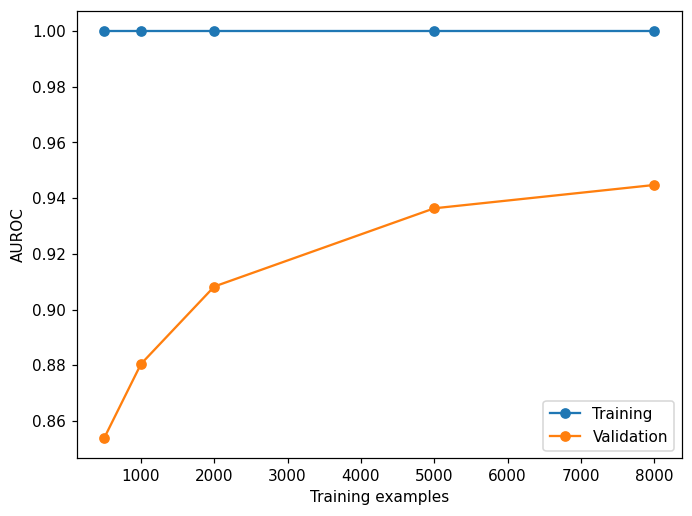

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
class_indices = [rng.permutation(np.flatnonzero(y_train.to_numpy() == label))
                 for label in [0, 1]]
learning_rows = []
for size in [500, 1000, 2000, 5000, 8000]:
    indices = np.concatenate([positions[:size // 2] for positions in class_indices])
    subset_text = X_train.text.iloc[indices]
    subset_labels = y_train.iloc[indices]
    model = make_pipeline(best_ngram, best_C)
    model.fit(subset_text, subset_labels)
    learning_rows.append({
        'training_rows': size,
        'train_auroc': roc_auc_score(subset_labels, model.decision_function(subset_text)),
        'val_auroc': roc_auc_score(y_dev, model.decision_function(X_dev.text))})
learning_df = pd.DataFrame(learning_rows)
print(learning_df.to_string(index=False))
learning_df.to_csv(output_path / 'learning_curve.csv', index=False)
plt.plot(learning_df.training_rows, learning_df.train_auroc, 'o-', label='Training')
plt.plot(learning_df.training_rows, learning_df.val_auroc, 'o-', label='Validation')
plt.xlabel('Training examples')
plt.ylabel('AUROC')
plt.legend()
plt.tight_layout()
plt.show()

## Step 6: Use Unlabeled Text
I test whether learning vocabulary and IDF from training plus unlabeled text helps. SVM labels still come only from the 8,000 labeled training rows. Validation and test text are excluded from feature fitting. The SVM settings are unchanged, and both results use uncalibrated decision scores.

In [8]:
unlabeled_vectorizer = make_vectorizer(best_ngram)
unlabeled_vectorizer.fit(pd.concat([X_train.text, unlabeled_df.text], ignore_index=True))
unlabeled_model = LinearSVC(C=best_C, dual='auto', max_iter=10000,
                             random_state=RANDOM_STATE)
unlabeled_model.fit(unlabeled_vectorizer.transform(X_train.text), y_train)
unlabeled_auc = roc_auc_score(y_dev, unlabeled_model.decision_function(
    unlabeled_vectorizer.transform(X_dev.text)))
unlabeled_results = pd.DataFrame({
    'method': ['Supervised only', 'Training + unlabeled vocabulary/IDF'],
    'val_auroc': [float(best.val_auroc), unlabeled_auc]})
print(unlabeled_results.to_string(index=False))
print(f'Change: {unlabeled_auc - best.val_auroc:+.6f}')
unlabeled_results.to_csv(output_path / 'unlabeled_comparison.csv', index=False)

                             method  val_auroc
                    Supervised only   0.944737
Training + unlabeled vocabulary/IDF   0.944279
Change: -0.000458


## Step 7: Generalization and Errors
I compare three word-count groups and select the five most confident false positives and false negatives at probability threshold 0.5. False positive means human text classified as generated; false negative means generated text classified as human. Subgroup differences are descriptive and do not isolate the effect of length from topic or other differences.

In [9]:
validation = X_dev[['id']].copy()
validation['label'] = y_dev
validation['probability'] = dev_probability
validation['words'] = X_dev.text.str.split().str.len()
validation['length_bin'] = pd.cut(validation.words, [0, 150, 250, np.inf],
                                  labels=['<=150', '151-250', '>250'])
length_rows = []
for name, group in validation.groupby('length_bin', observed=True):
    length_rows.append({'length_bin': str(name), 'count': len(group),
                       'val_auroc': roc_auc_score(group.label, group.probability)})
length_df = pd.DataFrame(length_rows)
print(length_df.to_string(index=False))
false_positives = validation[(validation.label == 0) & (validation.probability >= 0.5)].nlargest(5, 'probability').copy()
false_negatives = validation[(validation.label == 1) & (validation.probability < 0.5)].nsmallest(5, 'probability').copy()
false_positives['error'] = 'FP'
false_negatives['error'] = 'FN'
errors = pd.concat([false_positives, false_negatives])
print(errors[['id', 'error', 'probability', 'words']].to_string(index=False))
validation.to_csv(output_path / 'validation_predictions.csv', index=False)
length_df.to_csv(output_path / 'length_bins.csv', index=False)
errors.to_csv(output_path / 'errors.csv', index=False)

length_bin  count  val_auroc
     <=150    403   0.935926
   151-250   1036   0.945724
      >250    561   0.958562
  id error  probability  words
4260    FP     0.974806    237
2225    FP     0.965443    132
3199    FP     0.954749    147
8286    FP     0.930323    200
3671    FP     0.925808    165
 385    FN     0.003822     98
 276    FN     0.005978    186
4136    FN     0.007004    172
2161    FN     0.021165    180
5810    FN     0.021570    344


## Step 8: Generate Test Predictions
Refit the selected supervised model with calibration on all 10,000 labeled rows. This refit is used only for test predictions; the validation scores above come from the 8,000-row training partition.

In [10]:
final_model = make_calibrated_model()
final_model.fit(train_df.text, train_df.label)
submission = pd.DataFrame({'id': test_df.id,
                           'label': final_model.predict_proba(test_df.text)[:, 1]})
sample_submission = pd.read_csv(data_path / 'sample_submission.csv')
submission = submission.set_index('id').loc[sample_submission.id].reset_index()
assert list(submission.columns) == ['id', 'label']
assert len(submission) == 3000 and submission.id.is_unique
assert set(submission.id) == set(test_df.id)
assert submission.label.between(0, 1).all() and np.isfinite(submission.label).all()
submission.to_csv(output_path / 'submission_svm_yx752.csv', index=False)
print('Saved 3,000 test predictions to svm_results/submission_svm_yx752.csv')

Saved 3,000 test predictions to svm_results/submission_svm_yx752.csv


## Results
The best configuration uses unigram/bigram TF-IDF and C=1, with training AUROC 1.000000 and validation AUROC 0.944737. Sigmoid calibration preserves this validation ranking. The gap suggests that fitting the training data perfectly does not imply perfect generalization. Validation AUROC rises from 0.853909 at 500 training rows to 0.944737 at 8,000 rows, with smaller gains at larger sizes.

Learning vocabulary and IDF from the additional unlabeled text gives 0.944279, a change of -0.000458. This experiment does not show a benefit on this split. The shortest group has AUROC 0.935926 versus 0.958562 for the longest group, although topic and class composition may also contribute to that difference.

The validation set is used to choose the configuration, so its score is a development estimate. It does not measure generalization to unseen generators or domains. The training/validation gap, learning curve, and length groups help show limits of this representation. A single split is also insufficient to establish whether a small change from unlabeled feature learning is reliable.